## 1. Dataset provenance and experiment design

**Dataset:** Mauna Loa Weekly Atmospheric CO2 Data, a historical dataset distributed with `statsmodels` and originating in the Scripps/Keeling atmospheric CO2 measurement record. The packaged snapshot covers **1958–2001**; it is **not current 2026 data**. The weekly time series contains **2,284 timestamps** (including missing readings) and one measured variable: concentration in parts per million (ppm).

- [Dataset documentation](https://www.statsmodels.org/stable/datasets/generated/co2.html)
- [Scripps CO2 Mauna Loa station and contemporary data](https://scrippsco2.ucsd.edu/data/atmospheric-co2-data/sampling-station-records/mauna-loa-observatory-hawaii/)
- [NOAA data portal](https://gml.noaa.gov/ccgg/trends/data.html)

**Self-contained execution:** A compressed copy of this historical source series is included in an **embedded data-loading code cell** so that no network access, separate spreadsheet, or `statsmodels` package is needed to rerun it. The compressed data retain the original missing observations and calendar dates. Source data are credited in the references.

**Target:** This week's recorded CO2 (`co2` in ppm). **Predictors:** measurements available by the *end of the preceding week*, historical rolling summaries, and publicly known calendar terms. This is a **one-week-ahead rolling prediction** evaluated with previous actual observations; it is **not** a 12-month autonomous forecast.

**Validation:** Time-ordered 70% training, 15% validation (model selection), 15% final test. No random row shuffling. Training transformations are fitted only to the training window during validation; after model selection, the winning model is refitted on train + validation before final holdout evaluation.

## 2. Import Python libraries and make the experiment reproducible

Only standard Python modules plus `pandas`, `numpy`, `matplotlib`, and `scikit-learn` are required. Package versions appear in the output.

In [1]:
import base64
import io
import zlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from IPython.display import display, Markdown

pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.figsize': (9, 3.9), 'font.size': 10, 'figure.dpi': 105})
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__, '| NumPy:', np.__version__, '| scikit-learn:', sklearn.__version__)

Python: 3.13.5
pandas: 2.2.3 | NumPy: 2.3.5 | scikit-learn: 1.8.0


## 3. Load the original weekly data

The payload below is *read from notebook metadata* rather than from the Internet. If the metadata are removed while copying individual cells, retrieve the original data with `statsmodels.api.datasets.co2.load_pandas().data`.

In [2]:
# Embedded data are stored once in notebook metadata and decoded at runtime.
# The data are historical measurements, not simulated or artificially created values.
try:
    from IPython import get_ipython
    notebook_data = None
    # This variable is injected during execution by the next code cell.
except ImportError as exc:
    raise RuntimeError('Please run this code in Jupyter.') from exc

# A self-contained lightweight loader: compressed dataset bytes are supplied
# by the following cell so the only submission file needed is this notebook.
print('Data-loader initialized. Run the next cell to decode the included CSV.')

Data-loader initialized. Run the next cell to decode the included CSV.


In [3]:
# Embedded source CSV (compressed; kept inside this notebook for offline execution).
# Data source: Mauna Loa weekly CO2 series as distributed by statsmodels.
DATA_B64 = (
    'eNptXUmuBLly2/ssvz9SY0jHMWyvvfH94VeKYBYZqkajUSA0paQYRAZe//d//t///Ou//rf+R9lj/fO0f+r+Vyvz3+X5+yfA/s8z/kD7dxOw1A'
    'NOBfcBh4B1njE7geNvrgNuAcvzr+9vu4Ya/9R+QO3VCnrNfx77/i79+7tSm7rw2/zTxr8XDWj+aRe4D9gFPJ82ZJF//3r3qaB3LwIW7/4IWNu/'
    '3t/t+WvQpdf++4Q/sMmk+5/y9tr/1Id+Y0PK83cW39+l0O/1/V0Hfpd/nkK/15mUlvoHlnHAKmCteXkfcJ8P4e7VP6RLy/r5kA/YBay+D6agnd'
    '17Z//bmeL3KoPl0WNy0PSYDnguGB39Af8umBz9H1hx087v0vUyH7CWA04F1wW2z1AfcAkYt/f8jqFMGsRQDPbPEX8MRMFSDlgUXGq/B6yfA11f'
    'S9/HVOsBq4L7gCbguc/re8oHrO2AXcD24OumX4MlpzP9GixZ8/RrYLJR06+BfrL5PuiWmu/DBS71Tgc8+zBl9vUxh3xhlttFl6NfH7t4f9eqNu'
    '7gVrvex66H3vwDFremreBWEztgnRn8mHxTsz3gMYfGs39AO2AX8JhDBo85yOI//sHy4j/+oR9wCVhLttAPuNQ97uMfRt66j3+o+RQ+4M5m+/EP'
    '7l1xMeZz/EP9BW65Aw6WKfblYPWwNQQ8Xvpr1B8wnFsGi0Y9B+NWdwX9Vj8ENt8Q7d4QiE3BLZbo4NkQbdlh3VPBT/f9+gEHz4ZsGbP7hmTwbM'
    'iWiYbfkC2LH35D9ntwDn5uSH1kzHFuSAKnm/mWrZvHzK+Wx8xzy2PmunjDhhQF97VLBnfXBTwbYvKZ5htisp/r1w1ZuCEmYH3EOgI0iYkfcLu9'
    'Z7A8EmcD9O5VwLB3WufHh5QDTgXXj5aRD2wBjwOUiT7gvsACBzgEDHsvCu4fYNg7HcfHhzTxDA4WN9hHQY/CVcDas2f4A5tG9lmODzE9uAOWrl'
    'Z8wFp+gesCK6K5ghHNTcGlt+6AEc25e/MxM3jG/IbgANcBt4AxJs/e/YaQcTnoFjcELOMas/sN2WnM6i6IN3kck/kzbQU/JvMHdgE/JnO1/JjM'
    'H9gInOeGsLs4YHl+gXYtafoN0W83bEhVcKm3OWBsiHavVRK2APd1xAtPMwUjIjQF93U/F0yG17kRIhO4Jc9xsGgC72BtErUdbI9E7VmOD7E85s'
    'eHdLXiA9byC1waysvxIZrAO1jKj5aR+FUBI/GjL/r4kPoL3Nk2Pz5kaoA+YESEImBLQb8eHzL1NA+YMmEHT0QgK3ZQM+EPGA5QW4YD/Ob5AZra'
    '5gHjenPL5mPS9T5gedQQHExB/4AxpgnYPGrzmP3ckAv83JBa5Is6cgZTcKm91+NDxgGXgB+TSd3HMZk00Tgm8wfyccxzQ/66bwX3NdE8N+QPHA'
    'JWd0E6ZnuubzdsSBEwkqgtYC3qbRxc6r3r8SFdc5sDRpSpCq7r0q5gDD6/dzAG8Xt9f5ehEfOANaXiDnpkp2/5OIqp4f6ApalPOGBkSqagXeBL'
    'FGwBIzHoCpoa9QFrCs31+AR9aAe41BsfsAx5fTtYa7b0D7jPNrbjH4aG6QOWqmfq4FZbPmD1fHURWJHumoJ39+Pc3t+R9jdq0HyoC9xq7AeMp8'
    'QSMKxAu2craMctzKtlRxqwBTxpQP0ek4N2TJhbjiDH/Pd5QeQGn8v/N1QV8BMvEjjPNfgDm4LrWsk81+BvoiVgreo3HNya5LTjDaZ6gwOWdu2t'
    'uV1suTnmdrFlSQvxYgoY8aIqmMLNAcMuioCRMPPid2a9HIzovwUM+utRcOWWH0cxNKYfMDEGASrR7WAw1XRwpSD6TwV3XnwJxkC+vZSgc/13BH'
    '06hVJ9HxZ/XQlGUTa8BKO4Uvfs0vtxFF1P9oAlZekOLr0tBwyX3o8rKPR7fX8XavN3Y7+/N3634Ej9t/OZ/rsW+v2O2WGDPUjL729q813bYSa/'
    'v/f3d3iqHvTj+7slb9BBP15geXvNoNPjt7uOQY2dbOSUoL9kIwXlDrKRvVkH2chvjf6SjVvGXLT/Cw+HKQ2qUrUBbg0r/SUbTS5DkI1Tvm7jra'
    '1gUEm0ZpCNkz8ZZKOMCbJx8q0D2ZjHbEUDZX/JRuM7X963traMt/ZQcOUNAdm4eENANi7pXq/Y2l+ykcDxko1khuMlG+lkx0s2ZjCCrAkYAZFb'
    'VgSCKmBpP1rGu9gUNI044xjv1Oz3gDnIHjDG7Aq6pTDY/a1dpHv3t3aVxfdzQ/7AImDtGi7HMXyPtl3BdY05EG23gCfalu+1cXBf3ac/HHT26Q'
    '+HIvs58XBQMB4OPLv92hDzDdGJzDdExzTfEN15c5PZAi6wrwqWxAUdMKLMUjBFmXF8SNdX5AGDSnoUXOqXDhhvbZro40NStHVw62PkgBFttXu8'
    'tYeAEXZ5zALVqQlY0sP2gPHW3gpaNthSr7B7wAgETcH1Aww6+t3kedxFUdLJwaXnfsAylPI6YFzvR8GtAWseH+LXuwqYr7eDW03mgHG9F4EuWL'
    'AVTwgWN+gWNwSsHpp5TBcsapOWLljUJktyweIP1O7nlUEc9YRgkcZ0waJ22ToXLGqXxYdg0WSXQrDo3yOeECzSmCFY6DpdsEhjumBRm4zpgkXa'
    'JRcs/sAtYORFM3SK97ersZ/fC26fp1hw+0vAeFMUBe26rht80RYwvynmq0osudihSixeElQJ4zGhSmQwMqUqYE2y13xVCZ3oPLrf36XqM2pCjO'
    'D8bUKM4Ig8IUboNoYYcYOWLTTECD2aECMYNIgRHFYMYgRfCQsx4vt74be7MjZSg/TAYdEgPfD1M0gPf+AksGHMLWCMqS3j8jcB4/Lz7C491Cbr'
    'dOmh9tTyuMevQu3gcY9dZnfpoQ4ZM6SHIWOG9EBym73SAxHg9koPXb49pIcMnvugS3LpIW2ISw/stQzSQzoOQzqkYBmaOBmkhxvc+kQySA8cBQ'
    'zSA2d9BumBo5VBemCrMUgPN7g1dbFXetiyIfsSo+2VHhZ/O6SHDGYx2l7pQWaH9KAt/dGtiw/pgakqg/TAWbRBeuCnpUF60P0M6YFDrUF6UNsM'
    '6UH9QEgPTE8tSA987gvSAwflBenhBk0v2IL0wKa9ID2wwS5ID7XJ7BXXm1s2RP8Ebg2gCxzjBdamnmG9HCNZ8Xo5xgyeDSHTXi/H2GWi4BiHfN'
    'HwGzJkQ4Js1DGDbByyyUE2DpkoyEYdM8jGIYsPslHHnHCAW8GtLmi9ZKNuiMEBFgHroynWAtmYjnjhhiiY34MLZCO7oAWykbPTBbKRTWaBbGQX'
    'tEA2cpBdL9m4Zcx92fsC2chSzgLZeINbk4H1ko2bdynIRn6eL5CNnCEskI36mU42pg0J1lG3LlhH3flgHTlAL7COHHoWWEc2ww3WkVtusI6c8W'
    '6wjpwb72Ad5S7toB9/gEsv2A5CMo9Zcb0XgQ0mUxRMFudFmEPtyAsv6wG3glttc6NwuhIdvVE4XU1m98LpOmV2L5xOoBdOV0vgMRmT2b2Cus4E'
    'HpOZsvjhJkNk4I5S6jz79BsyZUOm35ALXAfk4zBsSBHwbMiUG+Ll1mnnvdyanepGuXXtsk4vt77AiAhFwJpi3EbddWq5ESKrgBEiTcAIkUvBlJ'
    'PvKMmWoL+jNlvi+44ibbHiHdXaecyCDLAquDQWb9Rv6+Kjflu/Peq3OdXcqN9WM4z67QuMEFkVNDkje1C/TVHGwfLIuQdoEjcdrF3s3cFWxLTt'
    'ifptvmAOxvV+BIzr3RRccpPtQSE3WZyDMaaCtYgVB7jENu1BRXf9vl4dLEXsPcD1Azw3ZMlEXtFdTSbyiu60JK/orks2xCu665INCW1FxwxtRc'
    'f00u60Ti/tribHEWqLybeH2pLBUsTTBrh+gJFETQIXIkJVcP0AI8osAVOUCXBLNLQHsgtFWAeLMloBbjFDB+vMYMgu9C52sDx5zJBddPaQXWrj'
    'Iw7ZJU0UrELjrQvZhXgqB2sRew9wZdMO2eUCS82mHbKLHkfILmzaBbILm3aB7EIB2sEyJZQ7eK73TN3P9f7y0lZe2WXK7OEAv2K3g/W5xqy43g'
    '+BDSZTBAyTaQKGyWj3GJNn78gZFIycoShoaobllV2WfGbILuSXyiu7bFlSyC47tTwms2TnQ3ZZckYhu+jsIbvklsW7FwHrvLobNmQLmJKoAE09'
    'WHlllylf5LJLOuKFiFAELPoMdLC6C2oKLkmerUB2YTMskF3Y3gtkF/YMBbIL+6UC2eUGlUN2MJKoIWCQ6lPAeFbTrQvZhbJ0B+MVOQRMNFqAlu'
    '09ZBfdupBd1LRDdtGDC9mF43uF7ML2Xl/ZJYNl/ABr/QVujVz1lV3INusru9D9rK/sQvezvrKLdm8IkUPAyBmKgkvtvb5E65LFd9j7VtDtvQsY'
    '9r4E/GxIe2R2J1rblzGzCqL1As8N2bJOJ1rTmE60tkc2OYhW7R5E65buQbRumX1eDrC+RKvuUhCtS+5SEK26yQYHWBTc18EtPJq2gOW+YCu/Ih'
    '2MEMlftBEiu4L65nKwTM1tKohWju8VRKuCQbRq9yBa2YoriFZ6lQe4NGrXl2gVgwXROqV7gb13Aeu1nyBaL3BnkwHRarzzIFotdT8bQiGyvUTr'
    'V+FysLQfYH30grWXaKXA116ilW5ye4nWr1YVoF/vKeC53mQdDTXe9UtPOViSxTXUeLdHJvIa7/bIOr3Guz0yu9d4tyK75DXerchEXuPdiizJa7'
    'xblZZe492qjOk13u3Lewe4DzgF/JhMq/JFXuOdxvQa76tl8e6PgJ8b0opM5DXerci5GzZkCBgb8ghYi7rKhhrvdEZe451aeo13uiFe41237NK6'
    'XpEtir3zpd3uAE0+c8MBLgGr8mABbnVrDeXfnOg2lH9z4Gso/75ByxNF+Td72obyb37tNpR/qxVH+bduSJR/c+xoKP+ui40ryr/VtKP8O01UkR'
    'K/3TvqwDkWd9SBc5rdUQfOAbqjDpwDdEcdOFtxRx04W3GPOnCx4o6C8AQ2jGkKbrX3DrGGrbhDrGE76hBr2Do6xJpW5TNdrEljuljTqmydizWt'
    'SUsXa1JLF2takyW5WNOafJGLNa3K1rlYk8Z0sSZ9pos1F1iTC+oQa1qRTXax5gJLu3bekER1BU29TYdYwz6kv2LNli9aiDJVwDAZbdmKZkH9FW'
    'uWTBRiDT2BO8QajtodYo22hFiTwUizHwVTDtYh1nAK11+xxnh2iDWyeIg1iy8DxJrFJgOxRuwdYs2WJQVXuVPLWrJpQ6yhluMVa+jgxivWUPcB'
    'sYYz6gGxhgP0gFhzg0tj3IBYwxdsQKzhSzsg1rQiS2oYcwoYY24Bs8kMiDUctQfEGjbtAbGmtdTy5AwZPDlDk293saY1WZKLNTfoLsgEPElUBk'
    '8S1WUiF2tak11ysabRo35ArGlNjsPFmrR4QxJlAkYS9Si4r9N0sYYd9YBYwwFlQKzhMDEg1rRHFh9izU5gmAyPGWLNls/cSLOHgDUF/fGKNYuv'
    'DcQaaQmx5gJXnghijawTYo18EcSaLbMXPKuLgLWqZxgQazgDHBBrdD9DrOGgPyDWqBWHWMOxY0Ks4SOeEGtu0NS0J8QaNu0JsYYNdkKs4VA+Id'
    'awFU+INRyLJ8QaTg8miFYO0BNEayMia4JoZeuYIFobEVkTRGvr8plOtLYuS3KitXVZkhOtrcsXOdGaxnSiNc3uRGvrsngnWtuQiZxobV2+3YnW'
    'NKYTrWlMJ1qvlvUUl9oEv5q20eD3uoJ2nYLzq+m8DBeDT2HhrWQClq656AS/eoNLU5r58qtbxnR+9WqZ30rz5VcXLx786uLPBL+6eUzwq5vXCX'
    '5187eDX9XuBX5vCRhm3gWMxG8oaOqKJ/hVdggT/Gor/O3Br3IInuBX2aIN/Cobr4Ff5XM38KtsfQZ+lc3cwK8msCKsdwEjrDcF94+WEdYngQ2W'
    'UgTMlmIoa28jtTxjEiNnKGtvQzbEy9obkdiGsvY2U/fzVpoykZe1N5IkDGXtjfRoQ1l7m/LtXtZ+tTwmo2N6WXvq7mXtbcome1l7WqeXtacvsl'
    '8bYtiQImCZP8DaruPwv8PDCZWh4p0TP0PFO7/UDBXv7KwMFe8J9Ip3dlaGineOoYaK96tlsGc0e1S8sxUbKt6vlpEJDwEju05gejwa/g6PLilK'
    '3znxM5S+qxVH6btuSJS+q21G6Tsn0obSd05lDaXvHEMNpe98xAul79xyofT9anmuN0XGhb/Dwxa3UAzPBrtQDM+3bqEYvg2ZKBwg8eoLGk2bss'
    '4GkykKLjXDBY2m0Xt2QaNpJut0jaaZfJFrNBd4bojJhoRGs2TM0GgyeExmyeJDozFZfGg0OrtrNG3J7K7RtCW75BpNGtM1mrQhhg2ZCiYPtqDR'
    'XGDkTlvBfR2xazTpMixEhKXg1sRvQaPhhGpBo2FDWNBo2LgWNBo22AWNhunuBY2G33QLGo12D42GY/GCRsOuckGj4QC9oNGwaS9oNPpFodFcYB'
    '3ZikOj4fR4QaPRTQ6NRo8jNJoLPBtC2vGGRnOBpell2NBo2DY3NJo2pWU4wAwW7z4UNL2KGxpNAl2jacRs71ejsdQyTKYLeMakBHK/Gs2SLwqN'
    'ZslEodEQf7VfjYaervvVaLa0DI1myyaHRqOzh0azE3hMRscMjWbLJodGs2WTQ6NZqWVtP8BzQ3SXDBtSBSxd/dJ+NRqTzzQkUdwyNBqTiRYiwl'
    'AwJVEbGg1bx4ZGw95mQ6NpXSbaeDxWAXOavaHRcPa7odFcYEn014ZGwznYhkaTupfrNb2h0bC9b2g0nCtuaDTsqDc0GrXi0Gh0k0OjUYsLjUYP'
    'LjQaMq71QKOh0ONgqT9aFo+wTcA6JRqu59VovmE3wC226WBc7ylgXO9KYPCrW2YPfvVrMg5+NqQ/Mrvzq/1JLT8b0ou0dH61P/JFzq/2b/oa4D'
    '6gCfjZkDSm86u9yOzOr/YiX+T86gV+bkia3fnVXmR251dTd+dXL/Bj7/3LcAa4rm+3XxsS/OqW2Q03ZAhY1YOt5+VXLYNbIoKD54ZksLYfYHvE'
    'L60H/GqbcsE2QqQJWD3CVgVNXnzrAb/aBm9d8Ks3qA7QwXhF0n4Gv6rrDH6VYrGDkRIXASMlbgpe9g5+VbYO/KrYJvhVsXfwq1/dZ5WXX6UjLi'
    '+/+uWCAjS14vLyqxlsRU27gF9lKy7gV9neC/jV/hWDAlzHEHhJDWOagGEyj4DVLW4p+BmzypheDN+/SamDnxtyg97dBPzckF5lQ7wYvlfZZC+G'
    '703W6cXwvco6vRg+TeTF8An0Yvj+LTVxsHj3IWB9rg3xYvhepLsXw6f99GJ4dkEFxfDsWAqK4dNpLkSEoeC6rqIXw3OQKiiGb5a61+SCCorhm8'
    'nsGyHyUXBLLHYwaDRaUhTDE+nkYKTZU0FTey8ohtclRTG8flEUw1Oy52CkxEXAWtR7FxTDq21GMTwlzw5GROgKbsl+HTwhkk6zohj+Bj3CNgHL'
    'VIOtKIZn064ohu9FxnQH2L/cr4Pl7l5xvRNoau8VGg2bTIVGc4E1WVyFRsMGW6HRsL1XaDS9yYa4RtO/b1gHT87Q5dtdo+lNJnKNpjdZp2s0V/'
    'eTRHX5dtdoEugaTf9y1A6eJErX6RrN1bLO69sNGzIELL6fj4L2A6xdnVWFWMOpUYVYw1GmQqzhKFNfsWbLaYZYs2RMF2vowehgKZr9Vog1bLAV'
    'Yg1nAhViDQf9CrGGc+8KsYaT/AqxhnOwCrGG43uFWMP+s75izeYbArFmp+7V5F286ivWZDAiQldwZXsPsYZjR4NYw3lyg1jTv3UdDp7rTQl5g1'
    'jD7qJBrOE0u0Gs4QvWINawaTeINXxpG8QatvcGsYaDfoNYk7q7WNO7zO5iDZt2g1iTWrpY03tqeZzqSC2PUx2yJBdr+pD9dLHmAo/JDNkQF2v6'
    'kNldrEktXazp33exg6X8Ate1eBdrepfLYNgQU9A3ZAhYfD+15dmQJrMbkigGXazhxKxBrEl3aSEiFAVNnVV7xZotX7SRZicwWVx7xRppCbFGWk'
    'Ks2bzOEGv6w+sMsYajdoNYw1G7QaxRgw2xhtPCBrGGw26DWKNbF2KN7lKINWpcIdZw3GwQa/Q0Q6zheNQh1vBl6BBrrpa1aIzrEGs4RHaINf3L'
    'pTt4rneX7uEAc8u43pNAJ1rZtDuIVjaEDqKVDbaDaGXj6kG0xu8efyjVf/sfSvXfldqcjzUZ2UnUCzynb7KrTqJ2k491ErVTst1Bot7g/gEeW5'
    '6yLU6i9ikTOYnav2rX6iBR2WV1kKhpAw3OTbvH6XPLhdN/BIzTLwp6eqZgTQGog0Tll1cHidqfBEb4awJG+EvgVrPtIFHZQjtIVO0eJCon2x0k'
    'qq4zSFT9oiBR2bV2kKi6IUGiqoUGicoG3kGi9iZLqle620GiqjEGicrgAInKYWWAROWoNECiXmCdF+gkaqdn4wCJ2ofMXhG7l4D5eg8Uuvcp62'
    'wwmSJgcYsbAp4xLXU/JkNs7UChe1/yRV7ofoHVuw8F7YD8RV7ofoHHZLZ8phe69y1f5IXufQnohe59y5K80L1TujtQ6J4+0wvdu8kZeaE7+7qB'
    'Qvc+paUXurNfGih07zN1r6YJ0ohC9/d3OHltcCxF7+rCw7AJGFGPu3t9OxvFQH07R9KB+namtgbq2zmxGahv15ZR385Z7kB9O5v5QH17b7ykqG'
    '/XJUV9u35R1LfrF0V9O0fSgfp2Tn0H6tsvsKSgOVDf3ocsPuhHMsmJ+nY+7on69k6080R9O8emifr21D38nrYMv0eXbaK+nW1/or69m3R3/YUD'
    '64T+0omwmq/+krufMbdMFPrLkiWF/rKle+gvWz4z9Jct++n6y3ike+gvlPpO6C/jkSW5/nJ1/5jM1fJjMgkM/YUy5/nqL0RUzld/0S8K/WXJOk'
    'N/WbLJduVOE/pLt9QycieeaCEQTAX3dW0WgssQMB6G2j1Mhru7/sKhbUJ/YTua0F84TZrQX9iDTegvHMEn9BfOnSb0l6tlZM48ZlAHQ7oHdSDr'
    'DP1Fvz30F/bPE/qL2mboLxwIJvQXjssT+svV8mwImaFBf+FzN+gvnWgog/7CUcygv3AUM+gvHKzt1V+0ZThAHTMcIIV1e/UXuvP26i/kBOzVX7'
    'aM2WAypuBSgzXoL+ORMV1/uVp+bsigVNagv4wiW+f6yyiyeNdfRpVdcv1lFFmn6y+jyNa5/pJauv4yipym6y9pna6/jCKzu/4yHpko9BfdOkPu'
    'tBRc13GE/rLlNNeVOxn0F86yDPoLezCD/pIu2ILJ8Do3Ho+PgCV5MIP+wh7MoL9wemzQX9hgDfoLB2iD/tInf3voLxxMDfoLG6xBf+H3rEF/UY'
    'MN/UW3LvSXvmSd9YoIBv1FDy70Fw679uovZFzr1V/ohizoL2wyC/rLBZ7r/aTucb25ZcX1XgLG9W4CxvUeCtqxOAadOx1VxnTuNE3k3Clb3AJ3'
    'Oqqs07nTQfnnAnc6mszu3OnV8mwIPfAXuNPRZSLnTkeTJTl3OrpsiHOno8vszp2mMZ07HV2W5Nzp1fI4QHojL3Cn6YsMG/IouK/jcO50VBnTLg'
    'e4wJ2yW1vgTtmDLXCn45ENce50kF6wXu50y+wbGWATMEKkKWiagy1wp2ybC9wpW9wCd3qB2QGulzvdvHhwp2Kb4E7FNsGdbpnI6QVOShe4U92l'
    '4E7HwwcX3CkHlAXulOPRAneqBhvc6aDH3QZ3OkgW2eBOBwl8G9wp36UN7pRv3QZ3yva+wZ3yrdvgTgc9GDe409FknV7oznd+o9D9ahljDgHPmF'
    '1aeqE7G+xGofsY8kVe6D5G6v65IWOmlp8bMoZsnRe6D8pUNwrdx5Bd8kL3MWSXvNB9DDkjL3RP3b3QPS3eC91HTy2ruyBep/3aEC90H11m90L3'
    '0WRML3RPZ+SF7umIFyLCFPBEhJpaRkQoAmaT2Sh05xi3UejO0XCj0J1Ne6PQnV3QRqE7m/ZGoTs/VzcK3a+WteTZo9BdFx+F7uPhDYlCdw7QG4'
    'XubO8bhe6c/W4UunP2u1HoPirvZxS6q2eIQne19yh0J4vbDwrdL/Bc768ZOlgfuTYBeoTdBIYD/IZIB9P1DlCvt4NxvY3ABpNRsDxiCAGaGJeD'
    'Z8whS/JCd7L3/aDQfUxp6YXuV8tzQ755coDr6u4azfhmqg4ekzHZENdoxpSJXKMZJmO6RpO6u0aTluQaDfklB6vv5xCwPdcmu0aTWhqSqEfAlE'
    'QFuK7TXIgIQ8CICFXBJeHMwTrEOvYDjYZymwCXOBYHiz5CHaz1R/e6MxgaDbk1ByPNfgSMNLsraBfoPAOZtoPnelc+uNBoKGo7WDXC7gcaDeWf'
    'Aa58cKHRqGmHRqOnGRoNG2yBRkPZr4Ol6rkXaDRX9zrVMxRoNGPImOEAM3iu95cLcrBqhN0FGk1q6RrNMBnTNZrxfUU6eMYk2yzQaIYJ6BrN+B'
    'JEDp4bYrIk12jG9xUZoB2Ql+QaTWrpGs1YMrtrNPOR/XSNZmwBXaMZXyopwHXALuC5IUuW5BrNWLIk12iGybm7RpM22TWaMWV2QxKlLSOJ4v1c'
    'iDJLwIgIU0F9BjoYJvMI2JILKhBrUsuNNLsIWIu8iwPUoL8LxBp6LDsYSVRRUJ+BDsazmrsXvCK7gjt/e4g17H4LxBp2AgViDT2Wd4FYw56hQK'
    'zhWFwg1uhphljDAaVCrOEgVSHWUJYeYIqwFWINB+gKsSZ1Dwf45cEcLClAV4g1bO81/ue2cmkriNbU3YlWtvcKopVNpr5EK1lcfYnWJRP1y97r'
    'S7Ru+aIOe68EBtG6ZZODaNXuQbSu1PLckNz9c0PmIxM50couqL5E65bPDKJ1yexBtOqGGDZEwbMhJrMbbkgT8GyIXpuFR9NWcKm3qSBaLzCHyA'
    'qilU2mgmhli6sgWjlAVxCto6bu2d4riFbtHkTraNw9iFZ2axVEqy4piNYEFjjALWDp6i4qiFbdkCBa2SdXEK3svSuIVt3kIFrp/e5g5AzvkhqI'
    '1vHlqANMGXV7iVZyAu0lWil5bi/RSml2e4lWbVkR36uA9VHP0F6i1aR7u3KGhkJ3dgINhe7sQxoK3ceXHNsNhe6cMzQUul8ti6ltNhS6sxU3FL'
    'qzE2godGcf0lDoPp8EfkxmPqn7x2TmI9/uhe5pTC90H1tO0wvdx07dzw3Rb/dCd87WGgrdx5LP9EL3tMle6J7O3QvdOSI0FLpz/tlQ6J4u7YLJ'
    'JDA9mhoK3dmxNBS6s2k3FLqzbTYUuisYhe43uH+Ax2Q671IUuhM152DOGRoK3fWLotCdX+UNhe6cCTQUunMobyh0V3uPQnc9jih0VycQhe7jW4'
    'i1Owrd+dw7Ct0vMFLiLmCkxE3BrTGuo9A9dQ8HSGG3o9CdU/eOQnc2w/6KNTpRg8ksBd3iuoDVoza3dLGGDbZDrJlFluRizQV+bsgssiEu1swv'
    'W7g7xJpZZCIXa2aRdbpYM4t8pos18yuC7A6xJi3JxZob9EeTdq/Jg3WINZzw9Fes2dI9xJotizckUY+ALfnk/oo1eusWoswQMKLMVNA0C+oQa/'
    'gJ3CHW3KBp2O0Qazh17xBrtGWINewAO8QatuIOsUbXGWINe9oOsYatuEOsGSazB89gqWW99hNijZghxJqdWpb0Ku+vWJNbNg+R7y6NV6whgx0Q'
    'a/guDYg186s0BZge9QNiDdvmgFjD13tArGHTHhBr2DYHxBq2zQGxZpYMJpMZEGtmldldrJlNZnexZtJzdUCsmU2W5GLNrKn7yRmabLKLNbPJOl'
    '2smV3208WaG7RrSS7WzCaf6WLN1fJzQ2ZNLWu/Fu9izayyeBdr0s67WMNubUCsmSV1jySKW7pYw35+vGLNlolCrKHYMV6xRltuMM9Nwa2Z6oBY'
    'c4G1KZU0INawWxsQa9itDYg1FxjP6kfBlSeCWLP53CHWbN4liDVisBBrNp9miDVqsCHW6M6HWDMf+UznKtU2Q6zhGDch1kzilybEGra4CbFmEp'
    'U0IdbwBZsQayaRzBNizWzS3R3gbDKRO8DZBXSile19gmidTSZyopXNcIJonfSKnCBaJ2WVE0Rratlh70vAsPeu4OeLhszuROukhHyCaJ1DZg+i'
    'dcgZOdE6h0zkRGtakhOtaXYnWueQM3KidQ7ZZCda04YYNqQIWNyDmYD1UU87QbSys5ogWtNVdKI1XTAnWjlMTBCtfL0niNYEboRIBUv/AdaiSd'
    'R8iVYBQbRuPg4QrZuvDYhWmQhEq4IFNNpWcKtpTxCtnEBOEK26S0G0cqI7QbSy858gWtVgg2idNXWvS1saiFYOUgailU3bQLSyEzAQrRx2DUQr'
    'h10D0cpX0UC0srswEK2zS/cGkxkK3mM2jKlgjGkKbrVNQ1X8pEzVUBU/pyzJq+LnlP30qvg5ZSKvir/AYzJTJvKq+GmyIV4VnybyqvhJebKhKp'
    '5dkKEqfg7p7lXxc8h+elU8uyBDVTx7G0NV/OwyplfFp533qnh2/oaqePY2hqr4Czwmo5d2wWSGgGEy3HKDeVawNE2zDVXxnFEbquLZ3g1V8Wza'
    'hqp4ju+GqnjOvQ1V8bPwLkVVPDtVQ1U8O1VDVTzHd0NVvO5SVMWrbUZVPKevhqr4C4wQWRU0vQwLVfEcpBaq4jlELlTFX2DtP8BW9NIuVMXPKb'
    'NXXO8hYC0/Wp7rbTKRizVscQtiDVvcglgz6Wm5INbMJbO7WDOXdHex5ga9+yPguSEk6yyINZMy1QWxZhJRsCDWpCW5WDO3zB5iDXGq6xVrtnym'
    'izVpIhdr0kQu1swlm2zYkEfA4vs5FPQzmgKeDdGDc7GG/eeCWDOnLH4hiZoCRhKVwK13fkGs4dixINawySyINWxxC2INJ7oLYg0HvgWxhv3ngl'
    'jDmeqCWHOBreR1hlijBhtiDQe+BbGGA9+CWKN2FGKNbnKINRzjFsQaPbgQaxjcEGv4MmyINZM00w2x5gJr01u3IdZMeq5uiDVsRxtiDV/vDbFm'
    'UgK5Idbwnd8Qa+aSMV2smTu1/IxpjyzJxRqjILUh1liRMV2ssSJjulhjRdbpYo09siEu1tgjn+lijZXU8mMyaUwXa67uH5NJE7lYY0Q+bIg1V8'
    'tzQ3ZqWecFuljDfmlDrLFHdsnFmrTzLtaw+90Qa9ilb4g17II2xBq+3htiDRvChlgzpyxp4xWpYEkGuyHWcDDdEGu0ZYg1nBJviDVs7xtiDb9h'
    'N8QadoAbYg0nkBtiDWe/G2KNbkiINRw3N8SaafztIdbozodYw2FiQ6y5wAiRvqTPfyHWvEf8ghygAZ6IANMGWD3CLgU3+RAHwwHChwAslSLsC3'
    'r3JmBcb16SE632yJKcaL3BRcYFsLrFGYEd9r4VdHvXlmHvS8Bj71Vmd6L1dRcOOtFqRXbJidY0kROtVmRJTrSm2Scc4BYwHOBU0K6JnGhN6zR1'
    'gC+4rk12ovV11ADjhpiC+7pLQbQuaelE6xukXtBjnLaMEMkXbCNEVgU3mSHAwgYLsLYfYHvIgx0wiNb3aQlQUmKA4QBNQU6zHSyw9ymg2PsLrm'
    'zFQbTq1oFolZ0H0SpmCKJ1p+61ZTME0UpOoLxEawbP9aYbUl6idX8vbQHRyreugGjl+1lAtL5B/wXT9S4gWtniCqrirSbwjHmBdsAiYIy5BPyE'
    'SHYCBVXxVmVJXhV/gZ8bYi11/9yQ1NKr4q0l8OQMTfbTq+Kvlh+TSS29Kt6afJFXxVuTb/eqeKupZfX91DHbcy3esCFFwNKvI/aq+HRwXhX/Zo'
    'AOelV8ukteFc+XtqAqnq93QVU8W0dBVfxcX3svqIrnYFpQFc+2WVAV/0btF9wZjKr4N0sHeHIG48+Mqvg3eX5BU/9ZUBV/geWh1P0FTR11QVX8'
    'm386WBEREriywUZVvB5cVMXrEUdV/Jul/z8bI6GZ'
)
frame = pd.read_csv(io.BytesIO(zlib.decompress(base64.b64decode(DATA_B64))), parse_dates=['date'])
frame = frame.set_index('date').sort_index()
frame.index.name = 'Date'
frame = frame.rename(columns={'co2': 'CO2_ppm'})
assert frame.shape[0] == 2284
assert frame.index.is_monotonic_increasing
print(f'Loaded {len(frame):,} historical weekly timestamps, from {frame.index.min():%Y-%m-%d} to {frame.index.max():%Y-%m-%d}.')
display(frame.head())

Loaded 2,284 historical weekly timestamps, from 1958-03-29 to 2001-12-29.


,CO2_ppm
Date,
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4


## 4. Exploratory Data Analysis (EDA)

We begin with raw observations to avoid accidentally masking missing values. The tables summarize data completeness and distribution; charts describe long-term trends, seasonality, missing records, and historical relationships. **These EDA plots describe the full historical dataset; they are not used to select models or fit transformations.**

In [4]:
print('Dataset dimensions (rows, columns):', frame.shape)
print('Duplicated dates:', frame.index.duplicated().sum())
print('Time-step frequency:', pd.infer_freq(frame.index))
quality = pd.DataFrame({
    'Variable': ['CO2_ppm'],
    'Observed': [frame.CO2_ppm.notna().sum()],
    'Missing': [frame.CO2_ppm.isna().sum()],
    'Missing (%)': [100 * frame.CO2_ppm.isna().mean()],
    'Unit': ['parts per million (ppm)']
})
display(quality)
display(frame.CO2_ppm.describe().to_frame('CO2_ppm').T)
display(frame.head(8))

Dataset dimensions (rows, columns): (2284, 1)
Duplicated dates: 0
Time-step frequency: W-SAT


,Variable,Observed,Missing,Missing (%),Unit
0,CO2_ppm,2225,59,2.583,parts per million (ppm)


,count,mean,std,min,25%,50%,75%,max
CO2_ppm,2225.0,340.142,17.004,313.0,324.8,338.3,354.8,373.9


,CO2_ppm
Date,
1958-03-29,316.1
1958-04-05,317.3
1958-04-12,317.6
1958-04-19,317.5
1958-04-26,316.4
1958-05-03,316.9
1958-05-10,NaN
1958-05-17,317.5


### EDA Chart 1 — Weekly CO2 over time

The raw time series reveals the long-run direction and repeated seasonal movement. Gaps are left unfilled in this plot.

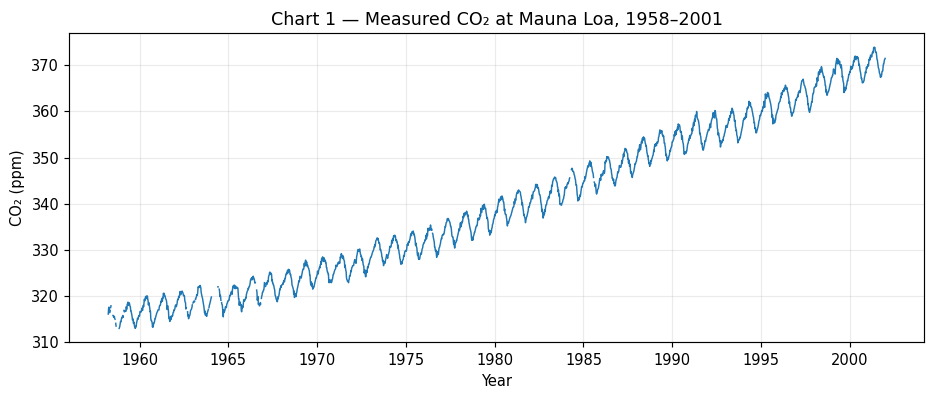

In [5]:
fig, ax = plt.subplots()
ax.plot(frame.index, frame.CO2_ppm, linewidth=1.0)
ax.set(title='Chart 1 — Measured CO₂ at Mauna Loa, 1958–2001', xlabel='Year', ylabel='CO₂ (ppm)')
ax.grid(alpha=0.25); plt.tight_layout(); plt.show()

### EDA Chart 2 — Yearly average CO2

Yearly aggregation smooths short-term variation and makes the multi-decade direction easier to observe.

,count,mean
Decade,,
1950,2,315.66
1960,10,320.15
1970,10,330.85
1980,10,345.27
1990,10,360.39
2000,2,370.11


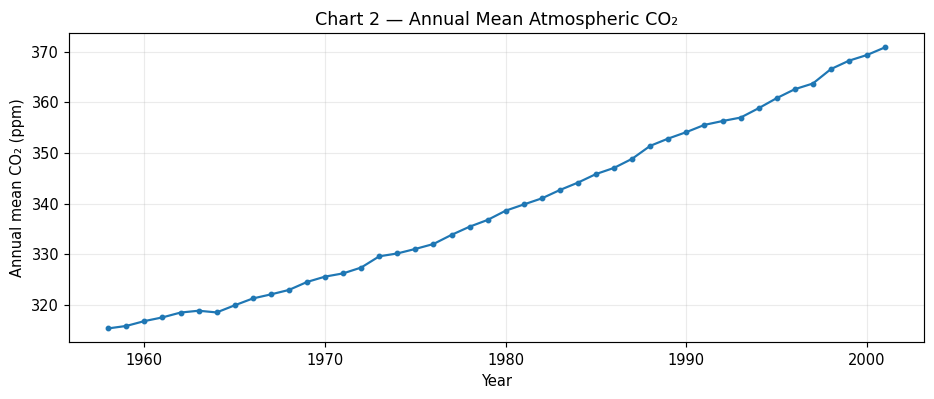

In [6]:
yearly = frame.CO2_ppm.resample('YE').mean().dropna()
display(yearly.groupby(yearly.index.year // 10 * 10).agg(['count','mean']).round(2).rename_axis('Decade'))
fig, ax = plt.subplots()
ax.plot(yearly.index.year, yearly.to_numpy(), marker='.', linewidth=1.5)
ax.set(title='Chart 2 — Annual Mean Atmospheric CO₂', xlabel='Year', ylabel='Annual mean CO₂ (ppm)')
ax.grid(alpha=0.25); plt.tight_layout(); plt.show()

### EDA Chart 3 — Distribution of observed concentrations

A histogram summarizes the absolute range of historical CO2, but should not be mistaken for a stationary distribution across decades.

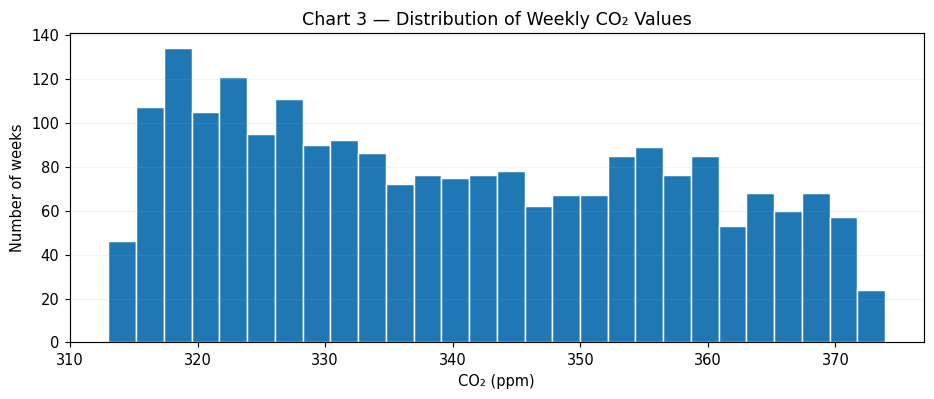

In [7]:
fig, ax = plt.subplots()
ax.hist(frame.CO2_ppm.dropna(), bins=28, edgecolor='white')
ax.set(title='Chart 3 — Distribution of Weekly CO₂ Values', xlabel='CO₂ (ppm)', ylabel='Number of weeks')
ax.grid(alpha=0.15, axis='y'); plt.tight_layout(); plt.show()

### EDA Chart 4 — Average concentration by calendar month

Simple monthly averages combine both seasonal effects and the long-term increase. Later feature engineering represents the calendar cyclically.

,mean,std,count
Month,,,
1,339.78,16.86,188
2,341.09,16.67,167
3,341.64,16.82,184
4,342.09,17.28,182
5,343.13,16.94,187
6,342.64,16.89,181
7,340.61,17.04,192
8,338.70,16.84,190
9,337.50,16.74,184


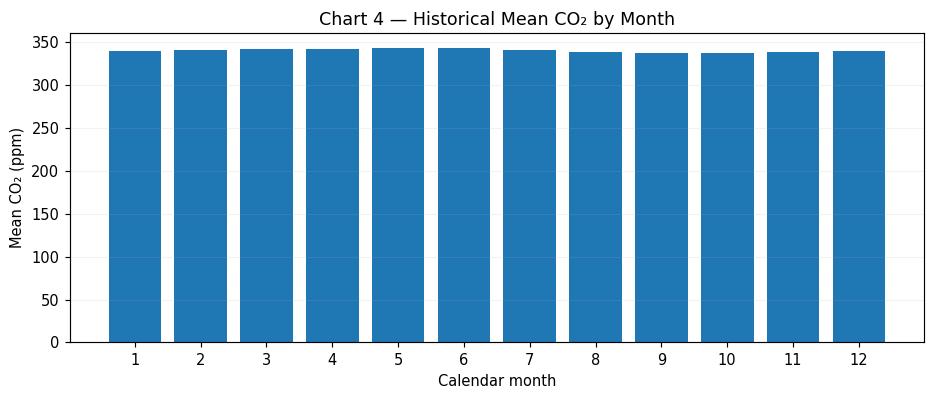

In [8]:
monthly_mean = frame.groupby(frame.index.month)['CO2_ppm'].agg(['mean','std','count'])
monthly_mean.index.name='Month'
display(monthly_mean.round(2))
fig, ax=plt.subplots()
ax.bar(monthly_mean.index.astype(str), monthly_mean['mean'])
ax.set(title='Chart 4 — Historical Mean CO₂ by Month', xlabel='Calendar month', ylabel='Mean CO₂ (ppm)')
ax.grid(alpha=0.15, axis='y'); plt.tight_layout(); plt.show()

### EDA Chart 5 — Seasonal distribution by month

The box plots display the range, variability, and potential outliers for each month across multiple years.

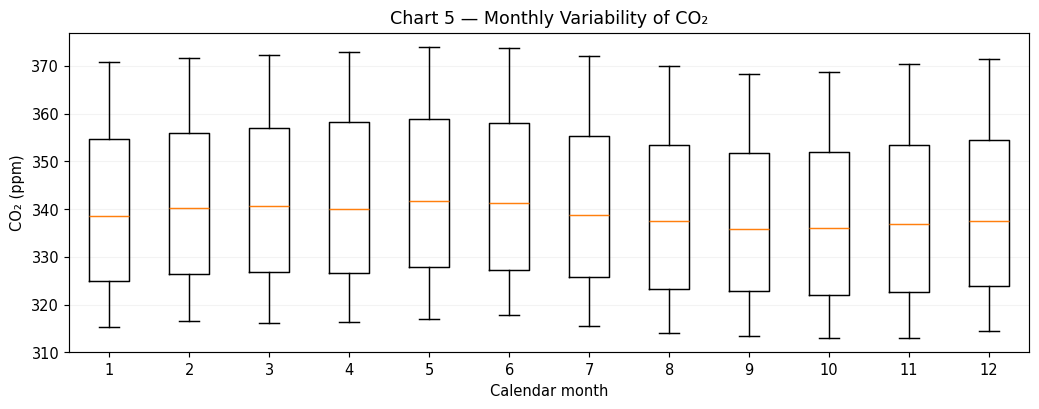

In [9]:
by_month=[frame.loc[frame.index.month==m,'CO2_ppm'].dropna().values for m in range(1,13)]
fig, ax=plt.subplots(figsize=(10,4))
ax.boxplot(by_month, tick_labels=[str(i) for i in range(1,13)], showfliers=False)
ax.set(title='Chart 5 — Monthly Variability of CO₂', xlabel='Calendar month', ylabel='CO₂ (ppm)')
ax.grid(alpha=0.15, axis='y'); plt.tight_layout(); plt.show()

### EDA Chart 6 — Missing observations per year

Missing values are important: it would be misleading to silently claim that every week was measured. In the predictive workflow, a missing label is excluded; lagged predictors can use the most recently observed concentration available at that time.

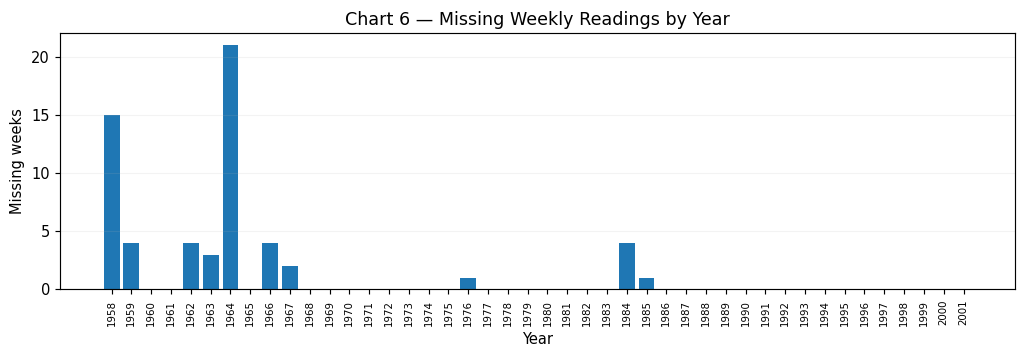

In [10]:
miss_by_year = frame.CO2_ppm.isna().groupby(frame.index.year).sum()
fig, ax=plt.subplots(figsize=(10,3.5))
ax.bar(miss_by_year.index.astype(str),miss_by_year.to_numpy())
ax.set(title='Chart 6 — Missing Weekly Readings by Year', xlabel='Year', ylabel='Missing weeks')
ax.tick_params(axis='x',labelrotation=90,labelsize=7)
ax.grid(alpha=0.15, axis='y'); plt.tight_layout(); plt.show()

### EDA Chart 7 — Approximate within-year variation

Subtracting each calendar year's mean helps visualize within-year seasonality separately from the long-term growth in absolute concentration.

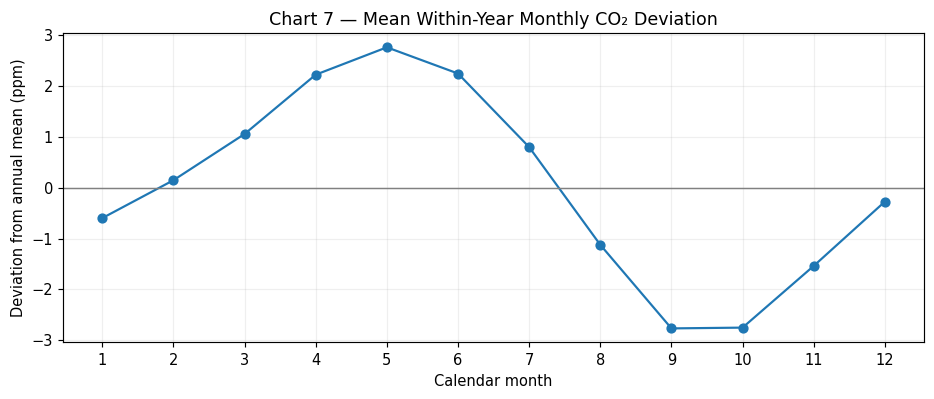

In [11]:
within_year = frame.CO2_ppm - frame.CO2_ppm.groupby(frame.index.year).transform('mean')
seasonal_dev = within_year.groupby(frame.index.month).mean()
fig, ax=plt.subplots()
ax.plot(seasonal_dev.index, seasonal_dev.values, marker='o')
ax.axhline(0,color='gray',linewidth=1)
ax.set(title='Chart 7 — Mean Within-Year Monthly CO₂ Deviation', xlabel='Calendar month', ylabel='Deviation from annual mean (ppm)')
ax.set_xticks(range(1,13)); ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

### EDA Chart 8 — Correlation at selected weekly lags

The series has substantial temporal persistence. High correlation alone does not prove model forecasting skill, because the trend inflates correlations across many lags.

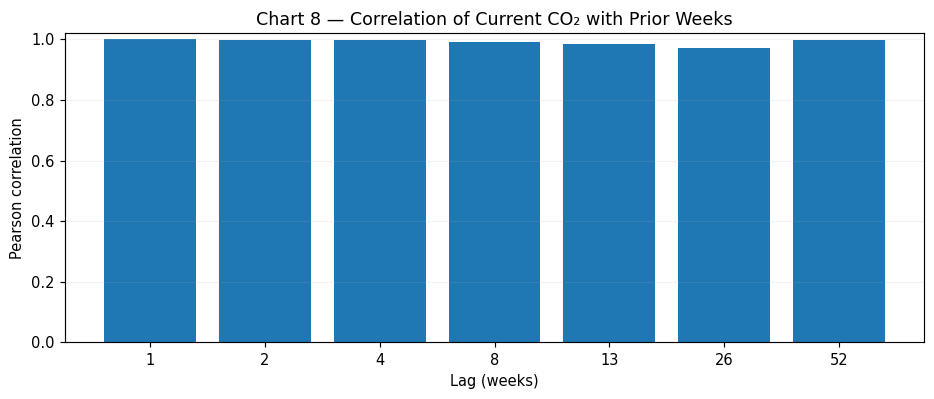

In [12]:
chosen_lags=[1,2,4,8,13,26,52]
lag_corr = pd.Series({lag:frame.CO2_ppm.corr(frame.CO2_ppm.shift(lag)) for lag in chosen_lags})
fig, ax=plt.subplots()
ax.bar([str(i) for i in lag_corr.index],lag_corr.to_numpy())
ax.set(title='Chart 8 — Correlation of Current CO₂ with Prior Weeks', xlabel='Lag (weeks)', ylabel='Pearson correlation')
ax.set_ylim(0,1.02); ax.grid(alpha=0.15, axis='y'); plt.tight_layout(); plt.show()

## 5. Preprocessing and feature engineering — no future-information leakage

To predict the measurement at timestamp `t`, predictors must be determined before `t` begins:

- `lag_1`, `lag_2`, `lag_4`, `lag_12`, `lag_26`, `lag_52` are earlier weekly readings (carried forward only from **past** observed readings for occasional missing weeks).
- `rolling_mean_4`, `rolling_mean_12`, and `rolling_std_12` summarize prior readings and are computed after a one-week shift.
- `year_trend`, `month_sin`, `month_cos`, `week_sin`, and `week_cos` encode the calendar known in advance.
- Weeks with missing target values are excluded from scoring and training.

**Causal filling:** `ffill()` uses only information from the past, never future outcomes. We do **not** interpolate with future readings, use random train/test splits, or compute rolling means on unshifted targets. This also means the fitted model predicts the next reading given recent observed measurements; evaluating it through the historical test interval assumes these prior measurements become available each week.

In [13]:
# Only lagged source values are forward filled. The label itself is never filled.
observed_history = frame['CO2_ppm'].ffill()
design = pd.DataFrame(index=frame.index)
design['target_ppm']=frame['CO2_ppm']
for n in [1,2,4,12,26,52]:
    design[f'lag_{n}']=observed_history.shift(n)
prior = observed_history.shift(1)
design['rolling_mean_4']=prior.rolling(4,min_periods=4).mean()
design['rolling_mean_12']=prior.rolling(12,min_periods=12).mean()
design['rolling_std_12']=prior.rolling(12,min_periods=12).std()
design['year_trend']=(design.index-design.index.min()).days/365.25
design['month_sin']=np.sin(2*np.pi*(design.index.month-1)/12)
design['month_cos']=np.cos(2*np.pi*(design.index.month-1)/12)
design['week_sin']=np.sin(2*np.pi*(design.index.isocalendar().week.astype(int)-1)/52.18)
design['week_cos']=np.cos(2*np.pi*(design.index.isocalendar().week.astype(int)-1)/52.18)
design = design.dropna().copy()
feature_cols=[c for c in design.columns if c!='target_ppm']
print('Weeks available after lag creation and missing-label removal:',len(design))
print('Features:',feature_cols)
display(design.head(4).round(3))
assert design.index.is_monotonic_increasing
assert not design.isna().any().any()

Weeks available after lag creation and missing-label removal: 2190
Features: ['lag_1', 'lag_2', 'lag_4', 'lag_12', 'lag_26', 'lag_52', 'rolling_mean_4', 'rolling_mean_12', 'rolling_std_12', 'year_trend', 'month_sin', 'month_cos', 'week_sin', 'week_cos']


,target_ppm,lag_1,lag_2,lag_4,lag_12,lag_26,...,rolling_std_12,year_trend,month_sin,month_cos,week_sin,week_cos
Date,,,,,,,,,,,,,
1959-03-28,316.7,316.7,316.8,316.6,315.2,313.5,...,0.672,0.997,0.866,0.5,0.992,0.126
1959-04-04,317.7,316.7,316.7,316.8,315.5,313.5,...,0.626,1.016,1.000,0.0,1.000,0.005
1959-04-11,317.1,317.7,316.7,316.8,315.6,313.5,...,0.708,1.035,1.000,0.0,0.993,-0.115
1959-04-18,317.6,317.1,317.7,316.7,315.8,313.5,...,0.683,1.054,1.000,0.0,0.972,-0.233


## 6. Chronological split

The earliest 70% of usable weeks are training data. The next 15% form the validation period used for model selection, and the final 15% are a truly held-out test period. Reporting the dates makes the experiment reproducible.

In [14]:
N=len(design)
cut_train=int(0.70*N); cut_val=int(0.85*N)
train=design.iloc[:cut_train]
valid=design.iloc[cut_train:cut_val]
test=design.iloc[cut_val:]
X_train, y_train=train[feature_cols],train['target_ppm']
X_valid, y_valid=valid[feature_cols],valid['target_ppm']
X_test, y_test=test[feature_cols],test['target_ppm']
windows=pd.DataFrame({
    'Window':['Training','Validation','Test'],
    'First date':[train.index.min().date(),valid.index.min().date(),test.index.min().date()],
    'Last date':[train.index.max().date(),valid.index.max().date(),test.index.max().date()],
    'Rows':[len(train),len(valid),len(test)]
})
display(windows)
assert train.index.max() < valid.index.min() < test.index.min()

,Window,First date,Last date,Rows
0,Training,1959-03-28,1989-05-27,1533
1,Validation,1989-06-03,1995-09-09,328
2,Test,1995-09-16,2001-12-29,329


## 7. Baseline and candidate machine-learning models

**Persistence baseline:** use the previous observed CO2 concentration as this week's prediction. This is a demanding baseline for an autocorrelated atmospheric series.

**Ridge regression** learns a regularized linear relationship using standardized features. **Random Forest** learns nonlinear interactions through an ensemble of decision trees. **Histogram-based Gradient Boosting** learns nonlinear effects from successive tree corrections. Hyperparameters were pre-specified for a compact comparison; we do not perform a large search over the holdout test set.

**Scoring:** MAE and RMSE are in ppm (lower is better); R² is unitless (higher is better).

In [15]:
models={
    'Ridge Regression':make_pipeline(StandardScaler(),Ridge(alpha=10.0)),
    'Random Forest':RandomForestRegressor(n_estimators=90,min_samples_leaf=3,max_features=0.8,n_jobs=-1,random_state=RANDOM_STATE),
    'Hist Gradient Boosting':HistGradientBoostingRegressor(max_iter=140,max_leaf_nodes=15,learning_rate=0.06,l2_regularization=0.5,random_state=RANDOM_STATE)
}
def metrics(actual,pred):
    return {
      'MAE_ppm':mean_absolute_error(actual,pred),
      'RMSE_ppm':np.sqrt(mean_squared_error(actual,pred)),
      'R2':r2_score(actual,pred)
    }
val_scores=[]
val_predictions={'Persistence baseline': X_valid['lag_1'].to_numpy()}
val_scores.append({'Model':'Persistence baseline',**metrics(y_valid,val_predictions['Persistence baseline'])})
for name, model in models.items():
    model.fit(X_train,y_train)
    pred=model.predict(X_valid)
    val_predictions[name]=pred
    val_scores.append({'Model':name,**metrics(y_valid,pred)})
validation_table=pd.DataFrame(val_scores).set_index('Model').sort_values('MAE_ppm')
display(validation_table.round(4))

,MAE_ppm,RMSE_ppm,R2
Model,,,
Ridge Regression,0.372,0.491,0.978
Persistence baseline,0.445,0.562,0.971
Random Forest,2.071,2.939,0.201
Hist Gradient Boosting,2.720,3.601,-0.199


## 8. Model selection without test contamination

The model with the lowest validation MAE is selected. The baseline is included as a genuine candidate: if all trained models underperform persistence, the proper conclusion is that additional complexity did **not** help on these historical observations. If a supervised model wins, it is refitted on training + validation; if persistence wins, no fitting is necessary.

In [16]:
winner=validation_table.index[0]
print('Selected by validation MAE:',winner)
X_trainval=pd.concat([X_train,X_valid]); y_trainval=pd.concat([y_train,y_valid])
if winner=='Persistence baseline':
    best_model=None
    best_pred=X_test['lag_1'].to_numpy()
else:
    best_model=clone(models[winner])
    best_model.fit(X_trainval,y_trainval)
    best_pred=best_model.predict(X_test)

# Honest test comparison: candidates are fixed before looking at test data.
test_scores=[{'Model':'Persistence baseline',**metrics(y_test,X_test['lag_1'].to_numpy())}]
for name,base_model in models.items():
    estimator=clone(base_model).fit(X_trainval,y_trainval)
    test_scores.append({'Model':name,**metrics(y_test,estimator.predict(X_test))})
test_table=pd.DataFrame(test_scores).set_index('Model').sort_values('MAE_ppm')
display(test_table.round(4))
print('Selected model test MAE (ppm):',round(metrics(y_test,best_pred)['MAE_ppm'],3))

Selected by validation MAE: Ridge Regression


,MAE_ppm,RMSE_ppm,R2
Model,,,
Persistence baseline,0.388,0.486,0.984
Ridge Regression,0.396,0.486,0.984
Random Forest,3.757,4.784,-0.574
Hist Gradient Boosting,4.156,5.146,-0.821


Selected model test MAE (ppm): 0.396


## 9. Visual diagnostic — observed versus predicted values

**Chart 9** plots the actual concentrations and the validation-selected model's weekly rolling predictions during the held-out time window. This chart is not another exploratory plot; it is a **test-set model diagnostic**.

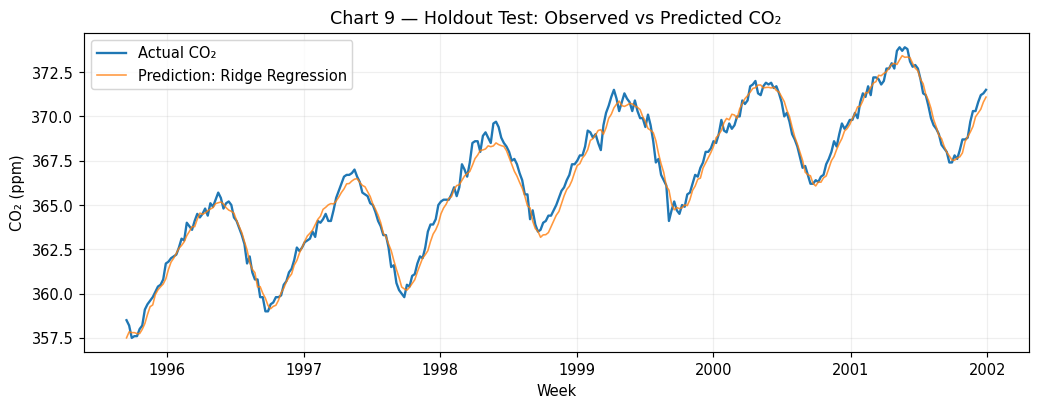

In [17]:
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(test.index,y_test.to_numpy(),label='Actual CO₂',linewidth=1.6)
ax.plot(test.index,best_pred,label=f'Prediction: {winner}',linewidth=1.1,alpha=0.8)
ax.set(title='Chart 9 — Holdout Test: Observed vs Predicted CO₂',xlabel='Week',ylabel='CO₂ (ppm)')
ax.legend();ax.grid(alpha=0.2);plt.tight_layout();plt.show()

## 10. Visual diagnostic — prediction error

**Chart 10** plots signed prediction errors. A persistent bias or outliers would motivate different lag choices, more frequent updated observations, or alternative trend specifications.

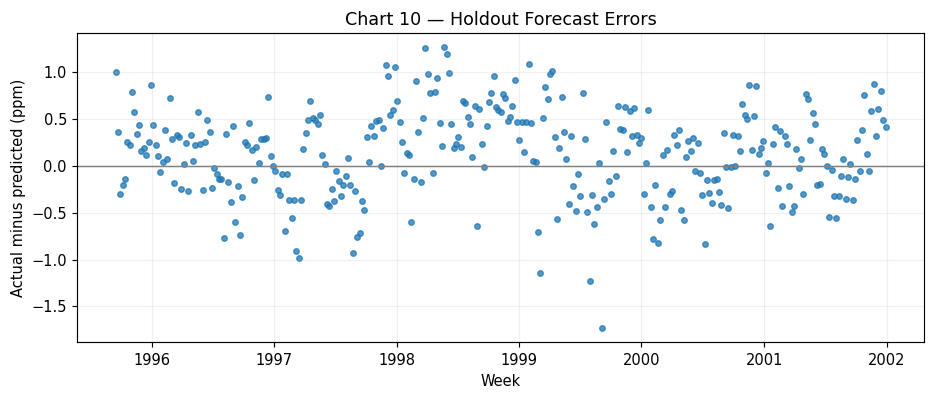

Mean signed error (bias): 0.134 ppm


In [18]:
test_resid=y_test.to_numpy()-best_pred
fig,ax=plt.subplots()
ax.scatter(test.index,test_resid,s=14,alpha=0.75)
ax.axhline(0,color='gray',linewidth=1)
ax.set(title='Chart 10 — Holdout Forecast Errors',xlabel='Week',ylabel='Actual minus predicted (ppm)')
ax.grid(alpha=0.18);plt.tight_layout();plt.show()
print('Mean signed error (bias):',round(float(np.mean(test_resid)),3),'ppm')

## 11. Feature importance (model interpretation)

If the selected model was trained rather than persistence, *permutation importance* evaluates how much shuffling each feature worsens held-out MAE. This is a descriptive measure of model reliance, not a causal statement. Lag variables are highly correlated, so individual rankings are not necessarily stable or independent. To avoid overinterpreting the holdout, use these values only for qualitative explanation, not for choosing a new model.

,Increase in MAE when shuffled (ppm)
lag_1,0.526
week_sin,0.497
lag_52,0.362
lag_2,0.314
rolling_mean_4,0.299
lag_26,0.294
lag_4,0.123
rolling_mean_12,0.069
month_cos,0.043
week_cos,0.035


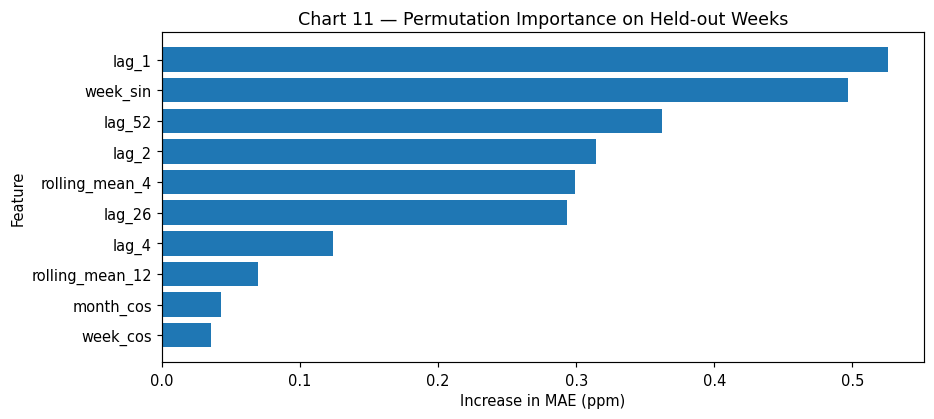

In [19]:
if best_model is not None:
    imp=permutation_importance(best_model,X_test,y_test,scoring='neg_mean_absolute_error',n_repeats=3,random_state=RANDOM_STATE,n_jobs=1)
    importance=pd.Series(imp.importances_mean,index=feature_cols).sort_values().tail(10)
    display(importance.sort_values(ascending=False).to_frame('Increase in MAE when shuffled (ppm)').round(3))
    fig,ax=plt.subplots(figsize=(9,4.1))
    ax.barh(importance.index,importance.values)
    ax.set(title='Chart 11 — Permutation Importance on Held-out Weeks',xlabel='Increase in MAE (ppm)',ylabel='Feature')
    plt.tight_layout();plt.show()
else:
    print('Persistence baseline selected; by definition it uses the previous available CO₂ reading only.')

## 12. Results, limitations, and conclusion

The following cell writes the numerical results **from the fitted experiment** so the conclusion is specific and honest. It compares MAE against the persistence baseline; negative improvement means the selected model was worse.

**Interpretation caveats:** The test period is historical, not a prediction for 2026. A rolling one-step-ahead evaluation may use newly observed concentrations as they arrive but cannot be interpreted as a long-horizon forecast. CO2 is affected by processes absent from this dataset; accurate one-step predictions do not imply that the models explain physical causation. Random Forest and tree boosting generally cannot extrapolate an upward time trend as directly as a linear model. The dataset's observation window also limits generalization to contemporary conditions.

In [20]:
selected_metrics=metrics(y_test,best_pred)
base_metrics=metrics(y_test,X_test['lag_1'].to_numpy())
mae_gain=100*(base_metrics['MAE_ppm']-selected_metrics['MAE_ppm'])/base_metrics['MAE_ppm']
print('FINAL EXAM CONCLUSION (generated from executed results)')
print(f'Dataset: {len(frame):,} historical weekly timestamps; {frame.CO2_ppm.isna().sum()} missing observations.')
print(f'Usable supervised examples: {len(design):,}; held-out test examples: {len(test):,}.')
print(f'Selected by validation: {winner}.')
print(f'Test MAE: {selected_metrics["MAE_ppm"]:.3f} ppm; RMSE: {selected_metrics["RMSE_ppm"]:.3f} ppm; R²: {selected_metrics["R2"]:.4f}.')
print(f'Persistence baseline test MAE: {base_metrics["MAE_ppm"]:.3f} ppm.')
print(f'Change in MAE relative to baseline: {mae_gain:+.2f}% (positive = improvement).')
if mae_gain>0:
    print('On the holdout period, the selected approach improved one-week-ahead MAE over persistence.')
else:
    print('The experiment did not demonstrate improved holdout MAE over persistence.')
print('Interpret results as historical, one-step-ahead predictions; not climate projections or causal evidence.')

FINAL EXAM CONCLUSION (generated from executed results)
Dataset: 2,284 historical weekly timestamps; 59 missing observations.
Usable supervised examples: 2,190; held-out test examples: 329.
Selected by validation: Ridge Regression.
Test MAE: 0.396 ppm; RMSE: 0.486 ppm; R²: 0.9837.
Persistence baseline test MAE: 0.388 ppm.
Change in MAE relative to baseline: -2.05% (positive = improvement).
The experiment did not demonstrate improved holdout MAE over persistence.
Interpret results as historical, one-step-ahead predictions; not climate projections or causal evidence.
